In [1]:
import geopandas as gpd
import regionmask
import xarray as xr
import os
import netCDF4
import matplotlib.pyplot as plt

In [ ]:
os.environ["SHAPE_RESTORE_SHX"] = "YES"

SHAPE_RESTORE_SHX = "YES"
algeria = gpd.read_file("dz.shp")   
ds = xr.open_dataset("data_stream-moda.nc",engine="netcdf4")

mask = regionmask.mask_geopandas(algeria, ds.longitude, ds.latitude)
ds = ds.where(mask.notnull())       
ds = ds.coarsen(latitude=2, longitude=256, boundary="trim").mean()

In [3]:
df = ds.to_dataframe()
df = df.dropna()
df = df.drop(columns=['number','expver'])
df = df.drop_duplicates()
df = df.reset_index()

df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,36.95,3.75,279.760498,284.346924,-5206072.0,7712772.0,-5404634.0,2.046784e+06,3.819242e-04,-0.002082,2.625080,0.556908,100893.875000,0.005114
1,2015-01-01,36.95,3.95,279.408936,283.862549,-4882846.0,7350362.0,-5204614.0,2.267892e+06,4.743487e-04,-0.001953,2.591389,0.508568,99983.875000,0.005336
2,2015-01-01,36.95,4.35,279.160889,283.442627,-5091602.0,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
3,2015-01-01,36.95,6.35,279.016846,282.479736,-4169095.5,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
4,2015-01-01,36.95,6.55,279.324310,282.819580,-4094020.0,7723036.5,-4838696.0,7.665407e+05,2.384782e-04,-0.001637,2.287352,-0.045143,98959.210938,0.004703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764779,2026-09-01,19.15,3.75,282.029541,307.469238,-203487.0,14447492.0,-9939245.0,-4.292967e+06,1.825392e-07,-0.000081,-0.867740,-1.067228,95788.187500,0.000088
764780,2026-09-01,19.15,3.95,282.064209,307.611816,-261701.5,14496558.0,-9942863.0,-4.281062e+06,2.868474e-07,-0.000105,-0.857364,-1.015471,95966.187500,0.000117
764781,2026-09-01,19.15,4.15,281.926025,307.671875,-213609.0,14506127.0,-9969803.0,-4.307196e+06,1.974404e-07,-0.000085,-0.849551,-0.996916,96068.687500,0.000079
764782,2026-09-01,19.15,4.35,281.761963,307.614258,-188365.0,14641952.0,-9969462.0,-4.458993e+06,7.078052e-08,-0.000075,-0.826602,-0.934172,96013.187500,0.000042


In [4]:
#infos
print(df.shape)
print(df.columns.to_list())

(764784, 15)
['valid_time', 'latitude', 'longitude', 'd2m', 't2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']


In [5]:
#kelvin to celcus
df['t2m'] = df['t2m'] - 273.15   
df['d2m'] = df['d2m'] - 273.15 

In [6]:
df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,36.95,3.75,6.610504,11.196930,-5206072.0,7712772.0,-5404634.0,2.046784e+06,3.819242e-04,-0.002082,2.625080,0.556908,100893.875000,0.005114
1,2015-01-01,36.95,3.95,6.258942,10.712555,-4882846.0,7350362.0,-5204614.0,2.267892e+06,4.743487e-04,-0.001953,2.591389,0.508568,99983.875000,0.005336
2,2015-01-01,36.95,4.35,6.010895,10.292633,-5091602.0,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
3,2015-01-01,36.95,6.35,5.866852,9.329742,-4169095.5,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
4,2015-01-01,36.95,6.55,6.174316,9.669586,-4094020.0,7723036.5,-4838696.0,7.665407e+05,2.384782e-04,-0.001637,2.287352,-0.045143,98959.210938,0.004703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764779,2026-09-01,19.15,3.75,8.879547,34.319244,-203487.0,14447492.0,-9939245.0,-4.292967e+06,1.825392e-07,-0.000081,-0.867740,-1.067228,95788.187500,0.000088
764780,2026-09-01,19.15,3.95,8.914215,34.461823,-261701.5,14496558.0,-9942863.0,-4.281062e+06,2.868474e-07,-0.000105,-0.857364,-1.015471,95966.187500,0.000117
764781,2026-09-01,19.15,4.15,8.776031,34.521881,-213609.0,14506127.0,-9969803.0,-4.307196e+06,1.974404e-07,-0.000085,-0.849551,-0.996916,96068.687500,0.000079
764782,2026-09-01,19.15,4.35,8.611969,34.464264,-188365.0,14641952.0,-9969462.0,-4.458993e+06,7.078052e-08,-0.000075,-0.826602,-0.934172,96013.187500,0.000042


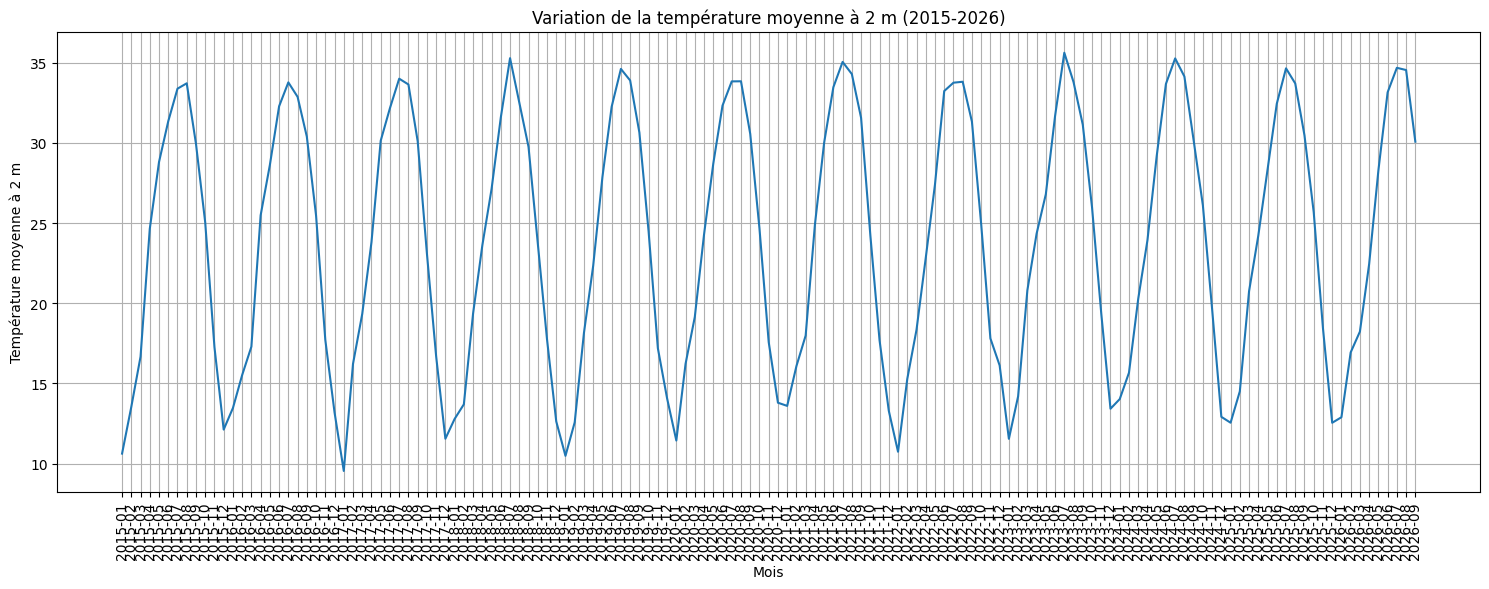

In [7]:
import pandas as pd
#variation de la temperature moyenne a 2m chaque mois entre 2015 et 2026
df['valid_time'] = pd.to_datetime(df['valid_time'])
monthly_temp = df.groupby(
    df['valid_time'].dt.to_period('M')
)['t2m'].mean()

plt.figure(figsize=(15, 6))

plt.plot(monthly_temp.index.astype(str), monthly_temp.values)

plt.title("Variation de la température moyenne à 2 m (2015-2026)")
plt.xlabel("Mois")
plt.ylabel("Température moyenne à 2 m")
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

# univariate analysis